# Assignment 8 – Data Wrangling: Real Estate Market

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

## 1. Import & Clean Column Names

In [2]:
df = pd.read_csv('RealEstate_Prices.csv')
print(df.shape)
df.head(3)

(414, 8)


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3


In [3]:
# Rename columns for clarity
df = df.drop(columns=['No'])
df.columns = ['transaction_date', 'house_age', 'dist_mrt',
              'convenience_stores', 'latitude', 'longitude', 'price_per_area']
print(df.dtypes)
df.head(3)

transaction_date      float64
house_age             float64
dist_mrt              float64
convenience_stores      int64
latitude              float64
longitude             float64
price_per_area        float64
dtype: object


,transaction_date,house_age,dist_mrt,convenience_stores,latitude,longitude,price_per_area
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3


## 2. Handle Missing Values

In [4]:
print('Missing values:')
print(df.isnull().sum())
# No missing values — confirm
print('\nDataset is complete — no imputation needed.')

Missing values:
transaction_date      0
house_age             0
dist_mrt              0
convenience_stores    0
latitude              0
longitude             0
price_per_area        0
dtype: int64

Dataset is complete — no imputation needed.


## 3. Filter & Subset

In [5]:
# Properties with price > 0 and reasonable age
df = df[df['price_per_area'] > 0]
df = df[df['house_age'] >= 0]
print('Shape after filter:', df.shape)

Shape after filter: (414, 7)


## 4. Handle Outliers

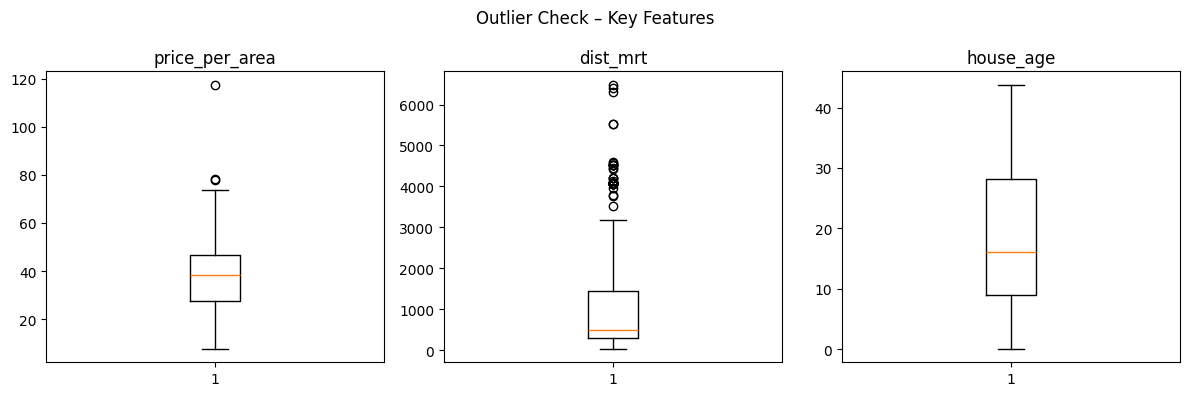

Shape after outlier removal: (411, 7)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ['price_per_area', 'dist_mrt', 'house_age']):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.suptitle('Outlier Check – Key Features')
plt.tight_layout()
plt.show()

# Remove price outliers using IQR
Q1, Q3 = df['price_per_area'].quantile([0.25, 0.75])
IQR = Q3 - Q1
df = df[df['price_per_area'].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]
print('Shape after outlier removal:', df.shape)

## 5. Encode Categorical Variables & Feature Engineering

In [7]:
# Bin distance to MRT into categories
df['mrt_category'] = pd.cut(df['dist_mrt'],
                            bins=[0, 500, 1500, 3000, df['dist_mrt'].max()],
                            labels=['Very Close', 'Close', 'Moderate', 'Far'])

# Bin house age
df['age_group'] = pd.cut(df['house_age'],
                         bins=[-1, 5, 15, 30, df['house_age'].max()],
                         labels=['New', 'Mid', 'Old', 'Very Old'])

df[['dist_mrt','mrt_category','house_age','age_group','price_per_area']].head(4)

,dist_mrt,mrt_category,house_age,age_group,price_per_area
0,84.87882,Very Close,32.0,Very Old,37.9
1,306.59470,Very Close,19.5,Old,42.2
2,561.98450,Close,13.3,Mid,47.3
3,561.98450,Close,13.3,Mid,54.8


## 6. Aggregate – Summary Statistics

In [8]:
agg = df.groupby('mrt_category', observed=True)['price_per_area'].agg(['mean','median','std','count'])
print(agg)

                   mean  median        std  count
mrt_category                                     
Very Close    45.588462    44.6   9.483933    208
Close         34.716346    36.1  10.162783    104
Moderate      26.391379    25.7   4.022842     58
Far           20.156098    18.3   8.319256     41


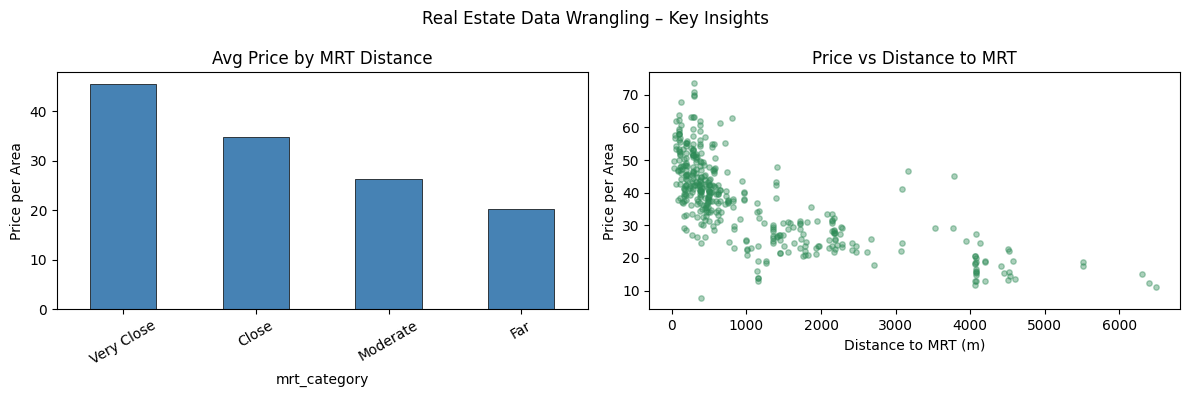

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Avg price by MRT distance category
agg['mean'].plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='k', linewidth=0.5)
axes[0].set_title('Avg Price by MRT Distance')
axes[0].set_ylabel('Price per Area')
axes[0].tick_params(axis='x', rotation=30)

# Price vs Distance scatter
axes[1].scatter(df['dist_mrt'], df['price_per_area'], alpha=0.4, s=15, color='seagreen')
axes[1].set_title('Price vs Distance to MRT')
axes[1].set_xlabel('Distance to MRT (m)')
axes[1].set_ylabel('Price per Area')

plt.suptitle('Real Estate Data Wrangling – Key Insights')
plt.tight_layout()
plt.show()

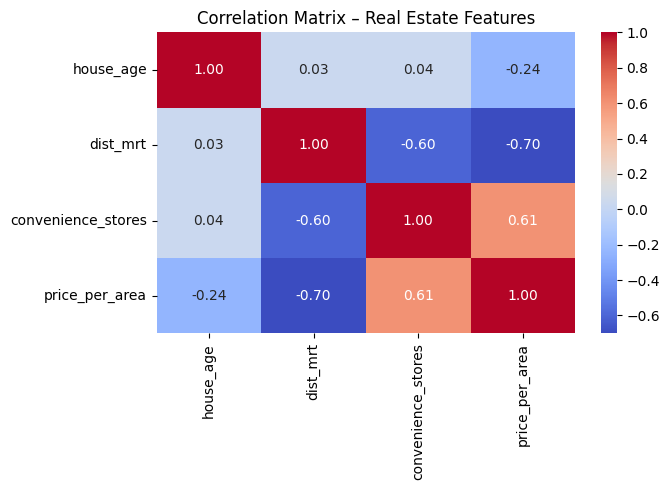

In [10]:
# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[['house_age','dist_mrt','convenience_stores','price_per_area']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix – Real Estate Features')
plt.tight_layout()
plt.show()